# The solar label

Every forecast is scored against `ads_ml_label_solar`, and M1 will be trained on it. Its label is TEPCO's delivered solar output plus the output TEPCO says it curtailed: what the weather allowed. The plan proposed that and left it to be confirmed on the data ([phase-1 plan](../docs/phase1/README.md#decisions), "Label on curtailed slots"). This notebook asks one question: **is `delivered + curtailed`, on usable slots, what the weather allowed?**

| Question | Where |
| --- | --- |
| What does TEPCO say the curtailed figure is, and is the file's figure the one it reports? | Section 1 |
| Where does curtailment sit: which days, which hours, how large? | Section 2 |
| On curtailed slots, does the sum follow the weather, as delivered output does on free slots? | Section 3 |
| Do the figures themselves show artifacts? | Section 4 |
| Is every label fit to train on and score against (F6)? | Section 5 |
| What does the choice touch downstream? | Section 6 |

The steps are in the order they were taken, the two that misled included (section 3), so the way to the answer can be followed and not only the answer.

It reads the label as built (the latest actuals, never as of `T`: [plan](../docs/phase1/README.md#point-in-time-rules), rule 4), and clear sky and capacity from `dws_solar_features`, as DWS knew them at each slot's decision time.

## 0. Setup

**Step.** `sql()` runs a query in the dev project and prints what it scanned. `SLOTS` is the one table the notebook reads: every labelled slot with its clear-sky output and capacity from `dws_solar_features`, and night from `dim_daylight`. Two words used throughout:

- A slot is **daylight** unless it is night, the metrics' filter ([notebook 05](05_clear_sky.ipynb), section 2)
- A slot is **lit** when clear sky allows at least 5% of capacity. Ratios to clear sky are read only on lit slots: near dawn and dusk they divide by almost nothing

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
pd.set_option("display.float_format", "{:,.3f}".format)


def setting(name: str) -> str:
    if value := os.environ.get(name):
        return value
    lines = Path("../.env").read_text().splitlines()
    env = dict(line.split("=", 1) for line in lines if "=" in line and not line.startswith("#"))
    return env[name]


PROJECT = setting("JTF_BIGQUERY_PROJECT")
PREFIX = setting("JTF_DBT_DATASET_PREFIX")
ADS, DWS, DIM = (f"{PROJECT}.{PREFIX}_{layer}" for layer in ("ads", "dws", "dim"))
bq = bigquery.Client(project=PROJECT, location=setting("JTF_BIGQUERY_LOCATION"))


def sql(query: str) -> pd.DataFrame:
    """Run a query in the dev project; print what it scanned and how long it took."""
    job = bq.query(query, job_config=bigquery.QueryJobConfig(use_query_cache=False))
    rows = job.to_dataframe(create_bqstorage_client=False)
    seconds = (job.ended - job.started).total_seconds()
    print(f"[{(job.total_bytes_processed or 0) / 1e6:.1f} MB scanned, {seconds:.0f} s in BigQuery]")
    return rows


# Every labelled slot with what DWS knew of it at its decision time, and whether it is night.
# A slot is "lit" when clear sky allows at least 5% of capacity: ratios to clear sky are read
# only there, since near dawn and dusk they divide by almost nothing.
SLOTS = f"""
SELECT l.slot_start, DATE(l.slot_start, 'Asia/Tokyo') AS day,
  FORMAT_TIMESTAMP('%H:%M', l.slot_start, 'Asia/Tokyo') AS slot,
  l.delivered_mw, l.curtailed_mw, l.label_mw, f.clear_sky_mw, f.capacity_mw,
  NOT n.is_night AS is_daylight,
  IFNULL(f.clear_sky_mw >= 0.05 * f.capacity_mw, FALSE) AS is_lit
FROM `{ADS}.ads_ml_label_solar` AS l
LEFT JOIN `{DWS}.dws_solar_features` AS f USING (slot_start)
LEFT JOIN `{DIM}.dim_daylight` AS n USING (slot_start)
"""

sql(f"""
SELECT COUNT(*) AS slots, COUNT(DISTINCT day) AS days, MIN(day) AS first_day, MAX(day) AS last_day,
  COUNTIF(clear_sky_mw IS NOT NULL) AS with_features, COUNTIF(is_daylight) AS daylight,
  COUNTIF(is_lit) AS lit, COUNTIF(curtailed_mw > 0) AS curtailed
FROM ({SLOTS})
""")

[4.3 MB scanned, 0 s in BigQuery]


,slots,days,first_day,last_day,with_features,daylight,lit,curtailed
0,49025,1022,2024-02-01,2026-11-18,48257,26226,22836,352


**What it shows.** 49,025 labelled slots on 1,022 days, from 1 February 2024 to the morning of 18 November 2026. 48,257 have features: the first target day is 17 February 2024. 26,226 are daylight, 22,836 of them lit, and 352 carry a curtailed figure.

## 1. What TEPCO says the figures are

### 1.1 The page's words

**Step.** The label's two terms are columns of TEPCO's monthly area file. Its page defines them and lists what to keep in mind.

**Observed**, on [TEPCO's area supply and demand page](https://www.tepco.co.jp/forecast/html/area_jukyu-j.html), read on 19 November 2026:

- **The two columns.** *"太陽光発電実績：太陽光発電所における発電電力量（30分値）"*, "Solar output: the energy generated at solar power stations (30-minute values)". *"太陽光出力制御量：太陽光発電所における出力抑制量（30分値）"*, "Solar curtailment: the amount of output held back at solar power stations (30-minute values)". The page doesn't say how the held-back amount is measured
- **Some of it is estimated.** *"発電実績は、推計実績を含んでいます。"*, "The generation results include estimated results."
- **It can change without notice.** *"公表値は、過去にさかのぼり修正させていただく場合があります。"*, "Published values may be revised retroactively." *"公表値を修正する場合に、修正のお知らせや修正前の需給実績の提供はいたしませんので、予めご了承ください。"*, "When we revise published values, we give no notice of the revision and don't provide the results as they were before it."
- **Output is what reaches the grid.** The values are at the sending end: *"発電所（太陽光を含む）の所内電力量や自家消費分を差し引いた送出地点の値で、実際に電力系統に送り出している値。"*, "the value at the point of sending out, after subtracting station use and self-consumption at power stations (solar included): what is actually sent into the grid."

**Learned → design:** the curtailed figure is TEPCO's own statement of output held back, of unknown method, in a file that includes estimates. Whether it measures what the weather allowed has to be shown on the data (section 3). Revisions without notice are why DWD versions every slot; none has been seen yet (Still open). Output net of self-consumption means the ratio to clear sky is below what the panels produce, a matter for notebook 09.

### 1.2 The file against TEPCO's curtailment reports

**Step.** TEPCO also reports each curtailment: the instruction it sent the day before (or the same morning) and the result. If the file's figure is the reported result, the column is TEPCO's official record of what it curtailed, not a by-product. The reported results are typed in below from the two reports ([fiscal 2026](https://www.tepco.co.jp/forecast/html/images/saiene_shijinaiyokon_jukyu.pdf), as of 9 November 2026; [fiscal 2025](https://www.tepco.co.jp/forecast/html/images/saiene_shijinaiyokako_jukyu_2025.pdf), as of 15 April 2026), row *"太陽光・風力出力制御量"*, "solar and wind curtailment", in 万kW (10 MW). The reports say what a result is: *"実績(速報)は制御量最大となる時間帯"*, "a result (preliminary) is for the time slot with the largest curtailment". So each is compared with the day's largest solar plus wind curtailment in the file, read from ODS, since DWD carries no wind curtailment.

In [2]:
# TEPCO's reported results per curtailed day, in 万kW (10 MW), typed from its two reports
# (fiscal 2025: as of 2026-04-15; fiscal 2026: as of 2026-11-09), row "太陽光・風力出力制御量",
# columns "実績"
REPORTED = pd.Series(
    {
        "2026-03-01": 181,
        "2026-03-08": 108,
        "2026-03-21": 43,
        "2026-03-28": 45,
        "2026-03-29": 329,
        "2026-04-05": 64,
        "2026-04-11": 168,
        "2026-04-12": 461,
        "2026-04-19": 280,
        "2026-04-25": 48,
        "2026-04-26": 137,
        "2026-05-02": 513,
        "2026-05-03": 2,
        "2026-05-04": 373,
        "2026-05-05": 633,
        "2026-05-06": 12,
        "2026-05-09": 428,
        "2026-05-10": 582,
        "2026-05-16": 305,
        "2026-05-17": 323,
        "2026-10-03": 59,
        "2026-10-18": 75,
        "2026-11-07": 51,
    },
    name="reported_10mw",
)
# Days with an instruction and a reported result of 0
INSTRUCTED_ONLY = [
    "2026-03-07",
    "2026-03-14",
    "2026-03-15",
    "2026-04-18",
    "2026-05-23",
    "2026-05-30",
    "2026-10-10",
    "2026-11-08",
]

file = sql(f"""
WITH latest AS (
  SELECT PARSE_DATE('%Y/%m/%d', date) AS day, time, solar_curtailed, wind_curtailed
  FROM `{PROJECT}.ods.tepco_actuals`
  QUALIFY ROW_NUMBER() OVER (PARTITION BY date, time ORDER BY fetched_at DESC, ingested_at DESC) = 1
)
SELECT CAST(day AS STRING) AS day, MAX(solar_curtailed) AS peak_solar_mw,
  MAX(wind_curtailed) AS peak_wind_mw, MAX(solar_curtailed + wind_curtailed) AS peak_both_mw,
  MAX_BY(time, solar_curtailed + wind_curtailed) AS peak_slot
FROM latest
GROUP BY day
HAVING peak_both_mw > 0
ORDER BY day
""").set_index("day")
both = file.join(REPORTED, how="outer")
both["file_10mw"] = both["peak_both_mw"] / 10
print(
    f"{len(file)} days with curtailment in the file, {len(REPORTED)} with a reported result; "
    f"in both: {int(both.notna().all(axis=1).sum())}; within rounding of each other: "
    f"{int(((both['file_10mw'] - both['reported_10mw']).abs() <= 0.5).sum())}; "
    f"instructed-only days with curtailment in the file: "
    f"{int(file.index.isin(INSTRUCTED_ONLY).sum())}"
)
both.T

[3.0 MB scanned, 0 s in BigQuery]
23 days with curtailment in the file, 23 with a reported result; in both: 23; within rounding of each other: 23; instructed-only days with curtailment in the file: 0


day,2026-03-01,2026-03-08,2026-03-21,2026-03-28,2026-03-29,2026-04-05,2026-04-11,2026-04-12,2026-04-19,2026-04-25,2026-04-26,2026-05-02,2026-05-03,2026-05-04,2026-05-05,2026-05-06,2026-05-09,2026-05-10,2026-05-16,2026-05-17,2026-10-03,2026-10-18,2026-11-07
peak_solar_mw,1756,1000,431,449,3269,635,1565,4379,2794,481,1361,4963,22,3411,6243,120,4134,5707,3051,3211,569,746,471
peak_wind_mw,51,81,3,5,21,7,115,278,5,0,20,185,0,317,264,0,193,197,5,34,19,0,41
peak_both_mw,1807,1081,433,453,3290,637,1677,4612,2798,481,1370,5128,22,3728,6333,120,4282,5817,3051,3235,587,746,512
peak_slot,12:00,12:00,11:30,12:30,11:30,10:00,11:30,11:30,11:30,11:00,11:30,12:00,11:00,12:30,10:30,11:00,12:00,11:00,11:30,11:00,9:30,10:30,11:00
reported_10mw,181,108,43,45,329,64,168,461,280,48,137,513,2,373,633,12,428,582,305,323,59,75,51
file_10mw,180.700,108.100,43.300,45.300,329.000,63.700,167.700,461.200,279.800,48.100,137.000,512.800,2.200,372.800,633.300,12.000,428.200,581.700,305.100,323.500,58.700,74.600,51.200


**What it shows.** **Observed:**

- **The same 23 days.** The file has curtailment on exactly the 23 days TEPCO reports a result above 0 for: 5 in fiscal 2025 (*"太陽光・風力出力制御日数：5日"*) and 18 in fiscal 2026 (*"18日"*)
- **The same figures.** On all 23, the file's largest solar plus wind curtailment equals the reported result to the report's rounding, from 20 MW (3 May) to 6,330 MW (5 May)
- **An instruction is not a curtailment.** The 8 days with an instruction and a reported result of 0 have no curtailment in the file
- **The first is 1 March 2026.** **Source**: [TEPCO Power Grid, 1 March 2026](https://www.tepco.co.jp/pg/company/press-information/press/2026/pdf/260301j0201.pdf): *"当社サービスエリア初となる再生可能エネルギー…の出力制御を実施しました"*, "we carried out the first curtailment of renewable energy in our service area". The file has none before it
- **Both are preliminary.** *"前日指示、速報値は修正する場合があります"*, "day-ahead instructions and preliminary values may be revised"

**Learned → design:** the file's curtailed figure is TEPCO's reported result, slot by slot. That settles what it is, not whether it is right.

## 2. Where curtailment sits

**Background: why solar is curtailed.** An area has to produce what it uses, moment by moment, and solar follows the sun, not demand. On a mild spring holiday demand is low while the sun is high, and at midday the area can have more power than it can use. Curtailment is TEPCO ordering renewable plants to hold output back then, and it is the last resort of the priority dispatch rules. **Source**: [TEPCO Power Grid, 1 March 2026](https://www.tepco.co.jp/pg/company/press-information/press/2026/pdf/260301j0201.pdf): *"火力発電所の運転抑制や揚水式水力発電所の上部調整池に水をくみ上げる揚水運転による需要の創出に加えて、地域間連系線を活用した当社サービスエリア外への送電などの対策を実施してもなお、電力需要に対して供給力が上回ると判断した場合、当社サービスエリア内の電力需給バランスを維持するため、…出力制御を実施いたします"*, "when supply is still judged to exceed demand after holding back thermal plants, creating demand by pumping water up at pumped-storage plants and sending power out of the area over the interconnectors, we carry out curtailment, to keep supply and demand in our service area in balance".

The same release gives the first curtailment in numbers, around noon on 1 March 2026 (preliminary):

| | 万kW | GW |
| --- | --- | --- |
| エリア需要, area demand | 2,543 | 25.4 |
| 揚水運転, pumping water up | 617 | 6.2 |
| 域外送電, sent out of the area | 0 | 0 |
| 小計, what the area could absorb | 3,160 | 31.6 |
| 供給力, supply (*"供給力は再エネ出力制御前の値"*, "supply is the value before curtailment"), 1,620 of it renewables | 3,344 | 33.4 |
| 再エネ出力制御量, curtailed | 184 | 1.8 |

The curtailed amount is the gap: 3,344 − 3,160 = 184. So on a curtailed slot, delivered output answers how much room demand left, not how bright the day was. That is the case for adding the curtailed figure back, if the figure can be trusted (section 3).

**Step.** Curtailed slots per month, with the energy held back and its share of the month's label; then each curtailed day; then the slots of the day.

In [3]:
sql(f"""
WITH slots AS ({SLOTS}),
by_day AS (
  SELECT day, COUNTIF(curtailed_mw > 0) AS slots, SUM(curtailed_mw) / 2 AS curtailed_mwh,
    SUM(label_mw) / 2 AS label_mwh
  FROM slots GROUP BY day
)
SELECT FORMAT_DATE('%Y-%m', day) AS month, COUNT(*) AS days, COUNTIF(slots > 0) AS curtailed_days,
  SUM(slots) AS curtailed_slots, ROUND(SUM(curtailed_mwh) / 1000, 1) AS curtailed_gwh,
  ROUND(100 * SUM(curtailed_mwh) / SUM(label_mwh), 2) AS pct_of_month_label
FROM by_day
GROUP BY month
HAVING curtailed_days > 0
ORDER BY month
""")

[3.6 MB scanned, 0 s in BigQuery]


,month,days,curtailed_days,curtailed_slots,curtailed_gwh,pct_of_month_label
0,2026-03,31,5,68,25.000,1.040
1,2026-04,30,6,97,53.000,2.200
2,2026-05,31,9,152,165.700,5.620
3,2026-10,31,2,32,2.900,0.140
4,2026-11,18,1,3,0.400,0.050


In [4]:
sql(f"""
WITH slots AS ({SLOTS})
SELECT day, FORMAT_DATE('%a', day) AS weekday, COUNTIF(curtailed_mw > 0) AS slots,
  MIN(IF(curtailed_mw > 0, slot, NULL)) AS first_slot,
  MAX(IF(curtailed_mw > 0, slot, NULL)) AS last_slot,
  MAX(curtailed_mw) AS peak_curtailed_mw,
  ROUND(MAX(SAFE_DIVIDE(curtailed_mw, label_mw)), 3) AS peak_share_of_slot,
  ROUND(SUM(curtailed_mw) / SUM(label_mw), 3) AS share_of_day
FROM slots
GROUP BY day
HAVING slots > 0
ORDER BY day
""")

[3.6 MB scanned, 0 s in BigQuery]


,day,weekday,slots,first_slot,last_slot,peak_curtailed_mw,peak_share_of_slot,share_of_day
0,2026-03-01,Sun,4,11:00,12:30,"1,756.000",0.113,0.022
1,2026-03-08,Sun,16,08:00,15:30,"1,000.000",0.060,0.036
2,2026-03-21,Sat,16,08:00,15:30,431.000,0.028,0.023
3,2026-03-28,Sat,16,08:00,15:30,449.000,0.036,0.029
4,2026-03-29,Sun,16,08:00,15:30,"3,269.000",0.202,0.119
5,2026-04-05,Sun,16,08:00,15:30,635.000,0.065,0.034
6,2026-04-11,Sat,16,08:00,15:30,"1,565.000",0.094,0.049
7,2026-04-12,Sun,16,08:00,15:30,"4,379.000",0.252,0.176
8,2026-04-19,Sun,17,07:30,15:30,"2,794.000",0.214,0.120
9,2026-04-25,Sat,16,08:00,15:30,481.000,0.041,0.031


In [5]:
sql(f"""
WITH slots AS ({SLOTS})
SELECT slot, COUNT(*) AS curtailed_days, ROUND(AVG(curtailed_mw)) AS mean_mw,
  MAX(curtailed_mw) AS max_mw, COUNTIF(NOT is_lit) AS not_lit
FROM slots
WHERE curtailed_mw > 0
GROUP BY slot
ORDER BY slot
""").T

[4.0 MB scanned, 0 s in BigQuery]


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
slot,06:30,07:00,07:30,08:00,08:30,09:00,09:30,10:00,10:30,11:00,11:30,12:00,12:30,13:00,13:30,14:00,14:30,15:00,15:30
curtailed_days,1,3,5,21,21,21,21,21,21,23,23,23,22,21,21,21,21,21,21
mean_mw,191.000,978.000,"1,227.000",937.000,"1,203.000","1,367.000","1,525.000","1,771.000","1,956.000","1,893.000","1,968.000","1,992.000","1,943.000","1,717.000","1,341.000","1,125.000",776.000,562.000,353.000
max_mw,191.000,"1,488.000","1,953.000","4,045.000","4,706.000","5,221.000","5,704.000","6,048.000","6,243.000","6,084.000","6,089.000","5,881.000","5,686.000","5,152.000","4,982.000","4,785.000","4,182.000","3,156.000","1,184.000"
not_lit,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


**What it shows.** **Observed:**

- **All of it is in 2026, on 23 days:** 20 in March to May, 3 in October and November. 247 GWh held back in all; 5.6% of May's label, 2.2% of April's, about 1% of March's, almost nothing in autumn
- **Days of low demand.** 9 Saturdays, 11 Sundays, and 4 to 6 May, public holidays (**Source**: [Cabinet Office, public holidays](https://www8.cao.go.jp/chosei/shukujitsu/gaiyou.html), its list for 2026: 4 May みどりの日, 5 May こどもの日, 6 May 休日)
- **A block from 08:00 to 16:00.** 16 days have exactly the 16 slots from 08:00 to 15:30; 5 start earlier (06:30 to 07:30) and end with the same slot; 2 are short runs around noon, 1 March and 7 November, the two days instructed on the same morning. The reports give the same periods: *"8時00分～16時00分"* on most days, and for 10 May a result of *"6時30分～16時00分"*
- **Why a block.** **Source**: the [fiscal 2026 report](https://www.tepco.co.jp/forecast/html/images/saiene_shijinaiyokon_jukyu.pdf): an instruction names *"オフライン制御で確保する制御量"*, "the amount secured by offline control", and *"再エネ出力制御量の増減については需給状況を踏まえオンライン制御が可能な発電事業者にて対応"*, "increases and decreases in the curtailed amount are handled, in view of supply and demand, by generators that can be controlled online"
- **Instructed the evening before, or the same morning.** The reports give each instruction's time: for 3 October, *"10月2日(金)17時頃 (前日指示)"*, "about 17:00 on Friday 2 October (day-ahead instruction)". The two same-day ones went out at about 11:00 on 1 March and about 10:00 on 7 November (*"当日指示"*)
- **Size.** From 0.2% of a day's label (3 May, at most 22 MW) to 31% (5 May, 6,243 MW in one slot, 38% of that slot's label). Every curtailed slot is lit

**Learned → design:** curtailment is recent, rare (1.36% of daylight slots) and concentrated: sunny weekends and holidays in spring. No model trained before March 2026 has seen a curtailed day. With delivered output as the label that would be a change of regime in the newest months, driven by demand and not by weather; with the sum, nothing changes if the sum is right.

Whether a day will be curtailed is not known when its forecast is made: the instruction goes out about 17:00 on D−1, and the decision time is 09:00 on D−1. So it can't be an input to a forecast at `T`. M1 doesn't need it, since its label has the curtailed output added back. A price model will care, because a midday surplus is when prices fall, and it will need a signal known at `T`, not the instruction.

## 3. Is the sum what the weather allowed?

Nobody measured what curtailed plants would have produced, so the sum can only be checked against slots that weren't curtailed: the free slots beside a curtailed run, the free slots of the same day, and free days nearby.

This section is kept in the order it was worked out. Its first test gave the wrong answer, and the second nearly did. Both stay in, run, because how the wrong answers arise says something about solar data that the features will depend on.

### 3.1 A first look, by eye

**Step.** Three curtailed days: the first (1 March), the heaviest (5 May) and the latest (7 November). For each, output over clear-sky output through the day, for delivered output and for the sum, on lit slots; the curtailed run in grey. Clear-sky output is what the fleet would give as flat panels under a cloudless sky ([notebook 05](05_clear_sky.ipynb)), so the ratio says how much of a cloudless day's output arrived.

[5.1 MB scanned, 1 s in BigQuery]
1022 days, 23 with curtailment; 983 free days with lit slots


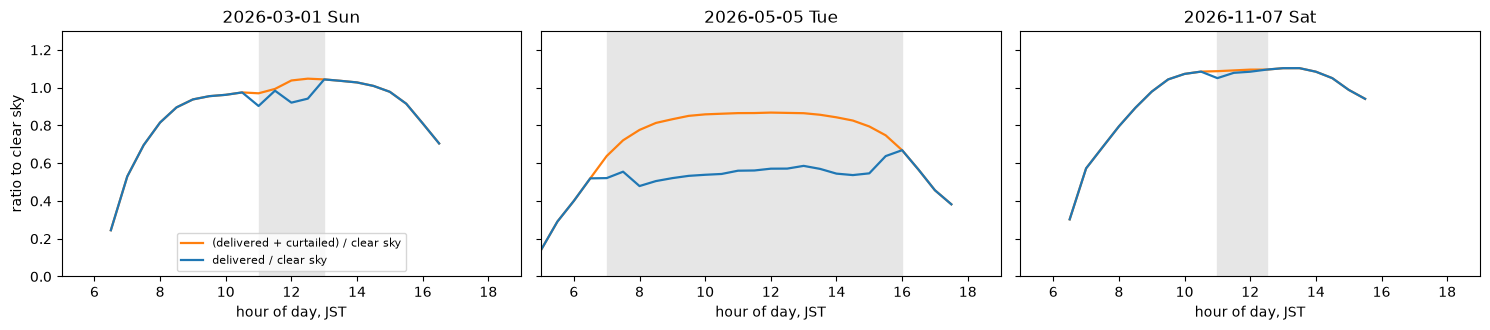

In [6]:
slots = sql(f"{SLOTS} ORDER BY slot_start")
slots["day"] = pd.to_datetime(slots["day"])
lit = slots["is_lit"].astype(bool)
slots["k_sum"] = (slots["label_mw"] / slots["clear_sky_mw"]).where(lit)
slots["k_delivered"] = (slots["delivered_mw"] / slots["clear_sky_mw"]).where(lit)


def grid(column: str) -> pd.DataFrame:
    """One row per day, one column per slot of the day."""
    return slots.pivot(index="day", columns="slot", values=column).asfreq("D")


K_SUM, K_DELIVERED = grid("k_sum"), grid("k_delivered")  # ratios to clear sky, lit slots only
CURTAILED = grid("curtailed_mw").gt(0)
curtailed_day = CURTAILED.any(axis=1)
# The days with no curtailment at all, the reference: curtailed days are blank rows in it
FREE = K_SUM.where(~curtailed_day, axis=0)
print(
    f"{len(K_SUM)} days, {int(curtailed_day.sum())} with curtailment; "
    f"{int(FREE.notna().any(axis=1).sum())} free days with lit slots"
)

hours = np.arange(48) / 2


def shade(ax, day) -> None:
    """Grey behind a day's curtailed run, from its first slot's start to its last slot's end."""
    block = CURTAILED.loc[day] | CURTAILED.loc[day].shift(fill_value=False)
    ax.fill_between(
        hours, 0, 1, where=block.to_numpy(), color="0.9", transform=ax.get_xaxis_transform()
    )


fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
for ax, day in zip(axes, pd.to_datetime(["2026-03-01", "2026-05-05", "2026-11-07"]), strict=True):
    shade(ax, day)
    ax.plot(
        hours,
        K_SUM.loc[day].to_numpy(),
        color="C1",
        lw=1.6,
        label="(delivered + curtailed) / clear sky",
    )
    ax.plot(
        hours, K_DELIVERED.loc[day].to_numpy(), color="C0", lw=1.6, label="delivered / clear sky"
    )
    ax.set(title=f"{day:%Y-%m-%d %a}", xlim=(5, 19), ylim=(0, 1.3), xlabel="hour of day, JST")
axes[0].set_ylabel("ratio to clear sky")
axes[0].legend(fontsize=8, loc="lower center")
fig.tight_layout()

**What it shows.** **Observed:**

- **The sum continues the curve; delivered output has a dent.** On 5 May delivered output sits near 0.55 through the block while the sum runs at 0.8 to 0.87, in line with the free slots before and after. On 1 March and 7 November the dent is small and short
- **The ratio is not flat even on a clear day.** On 1 March it climbs from 0.5 at 07:00 to about 1 by 10:00, and falls again after 15:00. Real panels are tilted, and clear-sky output here assumes flat ones

**Learned → design:** the sum looks right on three days picked by hand, which proves little. A test needs all 23 days and one number. That number is the **share lost**: how much of the curtailed figure is missing from delivered output. 1 means the figure is right; below 1, delivered output fell by less than the figure, so the sum overstates what the weather allowed; above 1, it understates.

### 3.2 A first test, which says the sum is too high

**Step.** Each curtailed run has two edges: the free slot before its first slot, and the free slot after its last. Weather moves little in half an hour, so the ratio in the curtailed slot should continue from its free neighbour. It can't be compared directly, since the ratio changes through the day (3.1). So the step from the free slot to the curtailed one is compared with the usual step between the same two slots: the median on the free days within 14 days either side. Per edge, the step into curtailment beyond the usual, for delivered output and for the sum. If the figure is right, delivered falls and the sum doesn't move.

In [7]:
WINDOW, ENOUGH = 29, 8  # a day's neighbours: 14 days either side, at least 8 of them free


def step(ratio: pd.DataFrame) -> pd.DataFrame:
    """Each slot's value minus the slot before it."""
    return ratio.diff(axis=1)


def nearby(free: pd.DataFrame):
    """A rolling view of the free days around each day."""
    return free.rolling(WINDOW, center=True, min_periods=ENOUGH)


before = CURTAILED.shift(axis=1, fill_value=False)
starts = CURTAILED & ~before  # the first curtailed slot of a run
ends = ~CURTAILED & before  # the first free slot after a run


def at_edges(at_start: pd.DataFrame, at_end: pd.DataFrame) -> pd.Series:
    """One value per edge of a curtailed run: `at_start` where a run starts, `at_end` where the
    first free slot follows one."""
    edges = [at_start.where(starts).stack(), at_end.where(ends).stack()]
    return pd.concat(edges, keys=["start", "end"], names=["edge", "day", "slot"])


def into_curtailment(ratio: pd.DataFrame, free: pd.DataFrame) -> pd.Series:
    """The value in the curtailed slot minus the free slot beside it, beyond the usual step
    between those two slots on free days nearby (their median)."""
    beyond = step(ratio).sub(nearby(step(free)).median())
    return at_edges(beyond, -beyond)


raw_edges = pd.DataFrame(
    {
        "delivered": into_curtailment(K_DELIVERED, FREE),
        "sum": into_curtailment(K_SUM, FREE),
    }
).dropna()
pd.DataFrame(
    {
        "edges": raw_edges.count(),
        "mean": raw_edges.mean(),
        "median": raw_edges.median(),
        "falls": (raw_edges < 0).sum(),
        "rises": (raw_edges > 0).sum(),
    }
)

,edges,mean,median,falls,rises
delivered,46,-0.013,-0.006,24,22
sum,46,0.025,0.028,9,37


**What it shows.** **Observed**, at 46 edges on 23 days:

- **The sum steps up, by 0.025 on average, at 37 of the 46 edges**
- **Delivered output hardly falls:** by 0.013 on average, and it falls at 24 edges and rises at 22

Read at face value, curtailment barely shows in delivered output, and adding the figure makes the output jump: the figure would be mostly fiction. But the plots in 3.1 show the dent plainly. One of the two is wrong.

### 3.3 Why the first test is wrong

**Step.** The suspect is the "usual step". It is a median over the free days nearby, bright and dull alike. Is the step between two slots the same on a bright day and a dull one? The free days of March to May, in thirds by their mean ratio to clear sky, with the mean step into 08:00 and into 16:00, the two slots where most runs start and end.

In [8]:
spring = FREE[FREE.index.month.isin([3, 4, 5])].dropna(how="all")
brightness = pd.qcut(spring.mean(axis=1), 3, labels=["dullest third", "middle third", "brightest"])
by_brightness = step(spring)[["08:00", "16:00"]].groupby(brightness, observed=True)
pd.DataFrame(
    {
        "free_days": brightness.value_counts(sort=False),
        "mean_ratio_to_clear_sky": spring.mean(axis=1).groupby(brightness, observed=True).mean(),
        "step_07:30_to_08:00": by_brightness["08:00"].mean(),
        "step_15:30_to_16:00": by_brightness["16:00"].mean(),
    }
)

,free_days,mean_ratio_to_clear_sky,step_07:30_to_08:00,step_15:30_to_16:00
dullest third,86,0.196,0.017,-0.018
middle third,85,0.515,0.046,-0.057
brightest,85,0.758,0.085,-0.088


**What it shows.** **Observed:**

- **Bright days step five times more than dull ones.** Into 08:00 the ratio rises by 0.085 on the brightest third and by 0.017 on the dullest; into 16:00 it falls by 0.088 and by 0.018
- **The usual step is a middling day's:** about 0.05 either way

Why: under a clear sky the light comes from the sun's direction, and tilted panels catch far more of it than flat ones while the sun is low, so the ratio to flat-panel clear sky changes fast in the morning and the evening. Under cloud the light comes from the whole sky, tilt matters little, and the ratio is nearly flat.

**Learned → design:** curtailment is ordered on bright days, and a bright day steps up into 08:00 by about 0.04 more than the usual, and down into 16:00 by 0.04 more, with nothing curtailed. Both count as a step up into the block. The first test measured how bright curtailed days are, not whether the figure is right. Two things follow. Here: compare only after taking the time of day out of the ratio. For the features: the ratio to flat-panel clear sky is not one number per day, which is notebook 09's question.

### 3.4 A scale that takes the time of day out

**Step.** Each slot's ratio is divided by what a clear day gives in that slot at that time of year: the 90th percentile of the same slot on the free days nearby. On this scale, the **level**, a clear day reads about 1 in every slot and a day half as bright about 0.5. `CUT` is the curtailed figure on the same scale. The check: the same thirds of free spring days as in 3.3, with their steps on the new scale.

In [9]:
# What a clear day gives in each slot at that time of year: the 90th percentile of the free
# neighbours. Dividing by it takes the time of day out of the ratio
clear_level = nearby(FREE).quantile(0.9)
R_SUM, R_DELIVERED, R_FREE = K_SUM / clear_level, K_DELIVERED / clear_level, FREE / clear_level
CUT = R_SUM - R_DELIVERED  # the curtailed figure on the same scale

spring_levels = R_FREE.loc[spring.index]
by_brightness = step(spring_levels)[["08:00", "16:00"]].groupby(brightness, observed=True)
pd.DataFrame(
    {
        "mean_level": spring_levels.mean(axis=1).groupby(brightness, observed=True).mean(),
        "step_07:30_to_08:00": by_brightness["08:00"].mean(),
        "step_15:30_to_16:00": by_brightness["16:00"].mean(),
    }
)

,mean_level,step_07:30_to_08:00,step_15:30_to_16:00
dullest third,0.272,-0.001,0.003
middle third,0.702,0.002,-0.007
brightest,0.939,0.008,-0.008


**What it shows.** On the level scale the steps into 08:00 and 16:00 are within 0.008 of zero in every third: a bright day and a dull one now step alike.

### 3.5 The edges again, on the level scale

**Step.** The test of 3.2 on levels. `free_days_spread` is how much the same step varies on free days nearby (the median distance from the usual). The edges are also grouped by the size of the curtailed figure in the slot: a run starts and ends gently, so many edges have little cut.

In [10]:
usual_step = nearby(step(R_FREE)).median()
spread = nearby(step(R_FREE).sub(usual_step).abs()).median()
edges = pd.DataFrame(
    {
        "cut": at_edges(CUT, CUT.shift(axis=1)),  # the curtailed slot's figure
        "delivered": into_curtailment(R_DELIVERED, R_FREE),
        "sum": into_curtailment(R_SUM, R_FREE),
        "free_days_spread": at_edges(spread, spread),
    }
).dropna()
print(
    f"{len(edges)} edges on {edges.index.get_level_values('day').nunique()} days; over all of "
    f"them: delivered {edges['delivered'].mean():+.3f}, sum {edges['sum'].mean():+.3f}, "
    f"sum rises at {(edges['sum'] > 0).sum()}"
)
size = pd.cut(edges["cut"], [0, 0.02, 0.05, 1], labels=["under 0.02", "0.02 to 0.05", "over 0.05"])
edges.groupby(size, observed=True).agg(
    edges=("cut", "size"),
    cut=("cut", "mean"),
    delivered=("delivered", "mean"),
    sum=("sum", "mean"),
    free_days_spread=("free_days_spread", "mean"),
    delivered_falls=("delivered", lambda s: (s < 0).sum()),
    sum_rises=("sum", lambda s: (s > 0).sum()),
)

46 edges on 23 days; over all of them: delivered -0.032, sum +0.017, sum rises at 32


,edges,cut,delivered,sum,free_days_spread,delivered_falls,sum_rises
cut,,,,,,,
under 0.02,12,0.008,0.001,0.009,0.011,6,7
0.02 to 0.05,21,0.035,-0.014,0.020,0.014,15,16
over 0.05,13,0.111,-0.092,0.018,0.011,12,9


**What it shows.** **Observed:**

- **Better, and still not clean.** Over all edges delivered output now falls by 0.032 and the sum rises by 0.017, at 32 of 46 edges
- **Where much was cut, delivered output falls by nearly the figure:** at the 13 edges with a cut above 0.05 of a clear day, by 0.092 for a figure of 0.111, at 12 of the 13
- **Where almost nothing was cut, nothing falls, and the sum still rises:** at the 12 edges with a cut under 0.02, delivered moves by +0.001 and the sum by +0.009

The last row matters in 3.7.

### 3.6 One number, and a second wrong answer

**Step.** The share lost, by least squares: `shortfall = share × cut` over the 46 edges, where the shortfall is delivered output's fall into the curtailed slot. With nothing cut, nothing should be short, so the line goes through zero. Its range is 95%, from resampling 5,000 times; whole days are resampled, not edges, because a day's two edges share its weather and don't count as two independent observations.

In [11]:
def share_lost(shortfall: pd.Series, cut: pd.Series, by_day, offset: bool) -> pd.Series:
    """Least squares for shortfall = share x cut, or with `offset` for
    shortfall = offset + share x cut. `share` is how much of the curtailed figure is missing
    from what was delivered. The 95% ranges come from resampling whole days 5,000 times."""
    sums = (
        pd.DataFrame({"n": 1.0, "x": cut, "y": shortfall, "xy": cut * shortfall, "xx": cut * cut})
        .groupby(np.asarray(by_day))
        .sum()
        .to_numpy()
    )

    def fit(s: np.ndarray) -> tuple:
        n, x, y, xy, xx = s.T
        if not offset:
            return xy / xx, 0 * xy
        share = (n * xy - x * y) / (n * xx - x * x)
        return share, (y - share * x) / n

    share, at_zero = fit(sums.sum(axis=0))
    picks = np.random.default_rng(8).integers(0, len(sums), size=(5000, len(sums)))
    shares, at_zeros = fit(sums[picks].sum(axis=1))
    return pd.Series(
        {
            "days": len(sums),
            "points": len(cut),
            "share_lost": share,
            "share_low": np.quantile(shares, 0.025),
            "share_high": np.quantile(shares, 0.975),
            "offset": at_zero,
            "offset_low": np.quantile(at_zeros, 0.025),
            "offset_high": np.quantile(at_zeros, 0.975),
        }
    )


edge_day = edges.index.get_level_values("day")
share_lost(-edges["delivered"], edges["cut"], edge_day, offset=False).to_frame("every edge").T

,days,points,share_lost,share_low,share_high,offset,offset_low,offset_high
every edge,23.000,46.000,0.819,0.672,0.892,0.000,0.000,0.000


**What it shows.** The share lost is 0.82, between 0.67 and 0.89. The range doesn't reach 1: delivered output falls by four fifths of the figure, so the sum would overstate what the weather allowed by a fifth of every curtailed MW. This was nearly this notebook's conclusion.

### 3.7 What the smallest cuts say

**Step.** Back to the table in 3.5. A figure a fifth too high makes the sum step up by a fifth of the cut: 0.002 where the cut is 0.008, and 0.022 where it is 0.111. The table shows 0.009 and 0.018. The step is nearly as large where almost nothing was cut, so most of it isn't the cut's doing. It belongs to the days and the hours: these are days TEPCO expected to be bright at midday (**Source**: [TEPCO Power Grid, 1 March 2026, the instruction](https://www.tepco.co.jp/pg/company/press-information/press/2026/pdf/260301j0101.pdf): *"昼間時間帯において、好天が予想され太陽光発電が高い出力となる一方、電力需要が低くなる見通しとなりました"*, "for the daytime, fine weather was forecast and solar output expected to be high, while demand was expected to be low"), and the block starts while such a day is still brightening and ends as it dims. Nothing happens to the weather at 08:00. The days weren't picked at random: days chosen for a bright midday are, on average, brighter at midday than in their mornings and evenings. A normal day shows no such step (3.4: within 0.008).

A line forced through zero has only its slope to explain a constant with, and it does so by tilting. So the same fit with an offset: `shortfall = offset + share × cut`. The offset is what these days do at an edge with nothing cut.

In [12]:
def by_edge(edge: str) -> pd.Series:
    side = edges.loc[edge]
    return share_lost(-side["delivered"], side["cut"], side.index.get_level_values("day"), True)


pd.DataFrame(
    {
        "every edge": share_lost(-edges["delivered"], edges["cut"], edge_day, offset=True),
        "starts": by_edge("start"),
        "ends": by_edge("end"),
    }
).T

,days,points,share_lost,share_low,share_high,offset,offset_low,offset_high
every edge,23.000,46.000,0.987,0.861,1.112,-0.016,-0.027,-0.006
starts,23.000,23.000,0.958,0.611,1.151,-0.018,-0.038,0.001
ends,23.000,23.000,1.041,0.833,1.213,-0.015,-0.030,-0.002


**What it shows.** **Observed:**

- **The share lost is 0.99, between 0.86 and 1.11.** Delivered output falls at the edges by the curtailed figure
- **The offset is −0.016, between −0.027 and −0.006:** with nothing cut, the level still rises by 0.016 going into the block. Its range doesn't reach 0
- **Starts and ends agree:** 0.96 and 1.04, each with a wider range

**A caution.** The offset was added after the first answer was seen, which is how a wished-for result gets made. What speaks for it is in the data, not in the answer: the step at edges with almost nothing cut, an offset whose range excludes 0, and the same answer from starts and ends separately. A reader who doesn't accept it has 0.82. Either way the sum is far nearer the truth than delivered output, which is off by the whole share lost.

**Learned → design:** at the edges, where the weather is held nearly fixed, the curtailed figure is what delivered output lost, to within about 14% of the figure either way. The offset is a correction inside this check and nothing more: it says how curtailed days were chosen, not what the weather does, and no model reads it.

### 3.8 The whole block against the day's free slots

**Step.** The edges test only the first and last slot of a run, where the least is cut. For the whole block from 08:00 to 16:00: a day's level in its free lit slots outside the block predicts its level inside, by a line fitted on the free days of the months that have curtailment. Each curtailed day's level inside, for the sum and for delivered output, is then compared with what its own free slots predict. Then the share lost again, both ways: this time with one point per day.

In [13]:
BLOCK = [f"{hour:02d}:{minute:02d}" for hour in range(8, 16) for minute in (0, 30)]
in_block = pd.Series(R_SUM.columns.isin(BLOCK), index=R_SUM.columns)
levels = pd.DataFrame(
    {
        "outside": R_SUM.where(~CURTAILED).loc[:, ~in_block].mean(axis=1),
        "slots_outside": R_SUM.where(~CURTAILED).loc[:, ~in_block].notna().sum(axis=1),
        "sum_inside": R_SUM.loc[:, in_block].mean(axis=1),
        "delivered_inside": R_DELIVERED.loc[:, in_block].mean(axis=1),
        "curtailed": curtailed_day,
    }
).dropna()

# What a day's free slots outside the block say about its level inside, learned on free days of
# the months that have curtailment
season = levels.index.month.isin([3, 4, 5, 10, 11])
free_days = levels[~levels["curtailed"] & season]
slope, intercept = np.polyfit(free_days["outside"], free_days["sum_inside"], 1)
unexplained = free_days["sum_inside"] - (intercept + slope * free_days["outside"])
print(
    f"{len(free_days)} free days: inside = {intercept:.3f} + {slope:.3f} x outside; "
    f"unexplained: mean {unexplained.mean():+.3f}, standard deviation {unexplained.std():.3f}; "
    f"on the {int((free_days['outside'] > 0.85).sum())} with outside above 0.85: "
    f"mean {unexplained[free_days['outside'] > 0.85].mean():+.3f}, "
    f"standard deviation {unexplained[free_days['outside'] > 0.85].std():.3f}"
)

curtailed_days = levels[levels["curtailed"]].drop(columns="curtailed").copy()
curtailed_days["expected_inside"] = intercept + slope * curtailed_days["outside"]
curtailed_days["cut"] = curtailed_days["sum_inside"] - curtailed_days["delivered_inside"]
curtailed_days["sum_gap"] = curtailed_days["sum_inside"] - curtailed_days["expected_inside"]
curtailed_days["delivered_gap"] = (
    curtailed_days["delivered_inside"] - curtailed_days["expected_inside"]
)
curtailed_days.rename(index=lambda day: f"{day:%Y-%m-%d %a}")

424 free days: inside = 0.022 + 0.985 x outside; unexplained: mean -0.000, standard deviation 0.114; on the 133 with outside above 0.85: mean -0.007, standard deviation 0.085


,outside,slots_outside,sum_inside,delivered_inside,expected_inside,cut,sum_gap,delivered_gap
day,,,,,,,,
2026-03-01 Sun,0.900,5,0.965,0.947,0.908,0.018,0.057,0.039
2026-03-08 Sun,0.998,5,1.032,0.994,1.005,0.038,0.028,-0.011
2026-03-21 Sat,1.005,7,1.012,0.987,1.012,0.026,0.001,-0.025
2026-03-28 Sat,0.699,7,0.833,0.807,0.710,0.026,0.122,0.096
2026-03-29 Sun,0.847,7,0.932,0.822,0.856,0.110,0.076,-0.034
2026-04-05 Sun,0.325,7,0.508,0.489,0.342,0.019,0.166,0.147
2026-04-11 Sat,0.942,8,1.016,0.964,0.950,0.052,0.066,0.014
2026-04-12 Sun,0.874,8,1.035,0.844,0.883,0.191,0.153,-0.038
2026-04-19 Sun,0.857,8,0.985,0.857,0.865,0.128,0.119,-0.009


In [14]:
heavy = curtailed_days["cut"] > 0.05
noise = unexplained.std()
by_weight = curtailed_days.groupby(heavy.map({True: "cut over 0.05", False: "cut up to 0.05"})).agg(
    days=("cut", "size"),
    cut=("cut", "mean"),
    sum_gap=("sum_gap", "mean"),
    delivered_gap=("delivered_gap", "mean"),
    sum_within_noise=("sum_gap", lambda s: (s.abs() <= noise).sum()),
    delivered_within_noise=("delivered_gap", lambda s: (s.abs() <= noise).sum()),
)
display(by_weight)
short = -curtailed_days["delivered_gap"]
pd.DataFrame(
    {
        "no offset": share_lost(short, curtailed_days["cut"], curtailed_days.index, offset=False),
        "with an offset": share_lost(
            short, curtailed_days["cut"], curtailed_days.index, offset=True
        ),
    }
).T

,days,cut,sum_gap,delivered_gap,sum_within_noise,delivered_within_noise
cut,,,,,,
cut over 0.05,12,0.165,0.107,-0.057,7,7
cut up to 0.05,11,0.018,0.055,0.037,8,9


,days,points,share_lost,share_low,share_high,offset,offset_low,offset_high
no offset,23.000,23.000,0.492,0.127,0.660,0.000,0.000,0.000
with an offset,23.000,23.000,0.820,0.496,1.026,-0.065,-0.104,-0.030


**What it shows.** **Observed:**

- **The free slots predict the block, loosely.** On 424 free days, inside = 0.022 + 0.985 × outside, with 0.114 left unexplained (standard deviation); 0.085 on the 133 bright ones. A day's cloud changes between morning and noon, so one day says little
- **Where much was cut, delivered output is below the prediction and the sum above it.** On the 12 days with a cut above 0.05 (0.165 on average), delivered sits 0.057 below and the sum 0.107 above
- **Where little was cut, both sit above it.** On the other 11 (0.018 on average), delivered sits 0.037 above and the sum 0.055 above. These days are brighter in the block than their mornings and evenings say, with nothing cut to explain it: the offset of 3.7 again, seen directly, and larger over a whole block than at its edges
- **The share lost is 0.82 with an offset, between 0.50 and 1.03.** Forced through zero it would read 0.49
- **Single days show the size of the noise.** On 4 May the sum sits 0.273 above the prediction and delivered output 0.194 above: a dull morning and a bright noon, not a wrong figure

**Learned → design:** over the whole block the estimate agrees with the edges and is much less sharp: 1 is inside its range, and so is a sum that overstates by half the figure. 23 days can't narrow it further. The edges are the better evidence, because the weather is held fixed there.

### 3.9 Against the clearest free days nearby

**Step.** A different angle, with no line to fit. A figure that overstated would push the sum above what any free day reaches. Per curtailed slot: is the sum's level above the highest level of the same slot on every free day within 14 days? If a curtailed day were a day like any other, that would happen once in (neighbours + 1) slots. The same count for delivered output. Then, where much was cut (a figure above 0.05 of a clear day), how far the sum stands above that highest neighbour as a share of the figure: the most the figure could be too high by, if the neighbour were the truth. Last, four curtailed days drawn in MW, with the level of a clear free day nearby (the 90th percentile, as in 3.4).

In [15]:
highest = nearby(R_FREE).max()
over = R_SUM.where(CURTAILED) / highest
over_delivered = R_DELIVERED.where(CURTAILED) / highest
neighbours = nearby(R_FREE).count().where(CURTAILED)
ceiling = pd.DataFrame(
    {
        "curtailed_lit_slots": [int(over.notna().sum().sum())],
        "sum_above_every_free_neighbour": [int((over > 1).sum().sum())],
        "delivered_above_every_free_neighbour": [int((over_delivered > 1).sum().sum())],
        "expected_if_a_day_like_any_other": [round(float((1 / (neighbours + 1)).sum().sum()), 1)],
        "sum_above_by_5pct": [int((over > 1.05).sum().sum())],
        "highest_sum_to_highest_neighbour": [float(over.max().max())],
    }
)
display(ceiling)
# How much of the curtailed figure the sum stands above the highest free neighbour by, where
# much was cut: the most the figure could be too high by, if that neighbour were the truth
above = ((R_SUM - highest) / CUT).where(CURTAILED & (CUT > 0.05)).stack()
above.describe(percentiles=[0.5, 0.9]).to_frame("share of the figure above the highest neighbour").T

,curtailed_lit_slots,sum_above_every_free_neighbour,delivered_above_every_free_neighbour,expected_if_a_day_like_any_other,sum_above_by_5pct,highest_sum_to_highest_neighbour
0,352,79,3,16.200,7,1.089


,count,mean,std,min,50%,90%,max
share of the figure above the highest neighbour,166.000,-0.415,0.684,-3.945,-0.165,0.127,0.471


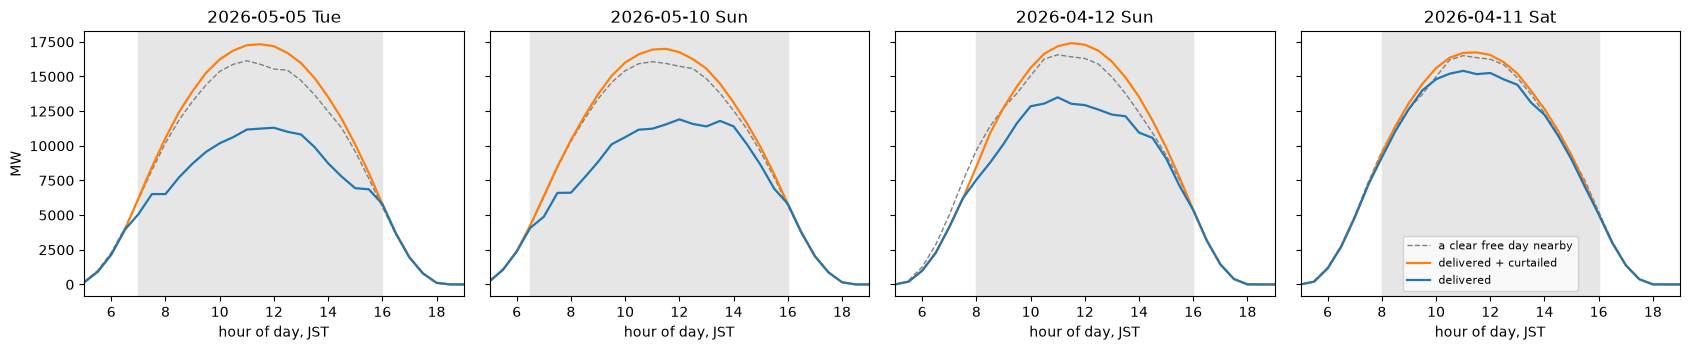

In [16]:
shown = curtailed_days.sort_values("cut").index[[-1, -2, -5, len(curtailed_days) // 2]]
mw = {name: grid(name) for name in ("delivered_mw", "label_mw", "clear_sky_mw")}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, day in zip(axes, shown, strict=True):
    ax.plot(
        hours,
        (clear_level.loc[day] * mw["clear_sky_mw"].loc[day]).to_numpy(),
        color="0.5",
        lw=1,
        ls="--",
        label="a clear free day nearby",
    )
    ax.plot(
        hours, mw["label_mw"].loc[day].to_numpy(), color="C1", lw=1.6, label="delivered + curtailed"
    )
    ax.plot(hours, mw["delivered_mw"].loc[day].to_numpy(), color="C0", lw=1.6, label="delivered")
    shade(ax, day)
    ax.set(title=f"{day:%Y-%m-%d %a}", xlim=(5, 19), xlabel="hour of day, JST")
axes[0].set_ylabel("MW")
axes[-1].legend(fontsize=8, loc="lower center")
fig.tight_layout()

**What it shows.** **Observed:**

- **The sum is above every free neighbour in 79 of 352 curtailed slots,** against 16 if these were days like any other; delivered output in 3
- **Never by much:** 7 slots are above by more than 5%, and the highest is 8.9% above
- **As a share of the figure, little.** In the 166 slots where much was cut, the sum is below the highest neighbour in more than half, above it by 0.13 of the figure or less in nine of ten, and by 0.47 of it in the worst
- **In the figures,** the sum follows the shape of a clear day through the block and sits slightly above it at noon; delivered output is cut off flat, by up to a third on 5 May

**Learned → design:** curtailed days aren't days like any other: they were chosen for a bright midday, so more of their slots should top their neighbours. That fits a sum that is right on the brightest days of their fortnight. It also leaves room for a figure somewhat too high: by about an eighth in most slots, if the brightest free day of the fortnight were as bright as the curtailed one, which agrees with the range at the edges. Delivered output alone is plainly not what the weather allowed.

## 4. The figures themselves

**Step.** Signs of a figure that was planned or rounded and not measured: values that aren't whole MW, values piling up on round numbers, the same value in consecutive slots. And delivered output repeating while curtailed, which would show a cap.

In [17]:
sql(f"""
WITH slots AS ({SLOTS}),
seq AS (
  SELECT *, LAG(curtailed_mw) OVER (ORDER BY slot_start) AS curtailed_before,
    LAG(delivered_mw) OVER (ORDER BY slot_start) AS delivered_before
  FROM slots
)
SELECT
  COUNTIF(curtailed_mw > 0) AS curtailed_slots,
  COUNTIF(curtailed_mw > 0 AND curtailed_mw != ROUND(curtailed_mw)) AS not_whole_mw,
  COUNT(DISTINCT IF(curtailed_mw > 0, curtailed_mw, NULL)) AS distinct_values,
  COUNTIF(curtailed_mw > 0 AND MOD(CAST(curtailed_mw AS INT64), 10) = 0) AS multiples_of_10,
  COUNTIF(curtailed_mw > 0 AND MOD(CAST(curtailed_mw AS INT64), 100) = 0) AS multiples_of_100,
  COUNTIF(curtailed_mw > 0 AND curtailed_mw = curtailed_before) AS curtailed_repeats,
  COUNTIF(curtailed_mw > 0 AND delivered_mw = delivered_before)
    AS delivered_repeats_while_curtailed,
  COUNTIF(is_lit AND curtailed_mw = 0 AND delivered_mw = delivered_before)
    AS delivered_repeats_elsewhere,
  COUNTIF(is_lit AND curtailed_mw = 0) AS lit_free_slots,
  COUNTIF(curtailed_mw > 0 AND delivered_mw = 0) AS curtailed_with_nothing_delivered,
  COUNTIF(curtailed_mw > 0 AND NOT is_daylight) AS curtailed_at_night
FROM seq
""").T

[4.7 MB scanned, 0 s in BigQuery]


,0
curtailed_slots,352
not_whole_mw,0
distinct_values,320
multiples_of_10,30
multiples_of_100,5
curtailed_repeats,3
delivered_repeats_while_curtailed,1
delivered_repeats_elsewhere,8
lit_free_slots,22484
curtailed_with_nothing_delivered,0


In [18]:
sql(f"""
WITH slots AS ({SLOTS}),
seq AS (
  SELECT *, LAG(delivered_mw) OVER (ORDER BY slot_start) AS delivered_before,
    LAG(curtailed_mw) OVER (ORDER BY slot_start) AS curtailed_before
  FROM slots
)
SELECT day, slot, delivered_before, delivered_mw, curtailed_before, curtailed_mw,
  ROUND(clear_sky_mw) AS clear_sky_mw
FROM seq
WHERE curtailed_mw > 0 AND delivered_mw = delivered_before
ORDER BY slot_start
""")

[4.0 MB scanned, 0 s in BigQuery]


,day,slot,delivered_before,delivered_mw,curtailed_before,curtailed_mw,clear_sky_mw
0,2026-05-05,08:00,"6,518.000","6,518.000","1,953.000","4,045.000","13,609.000"


**What it shows.** **Observed:**

- **Whole MW, like every column of the file,** 320 different values in 352 slots
- **No piling on round numbers:** 30 are multiples of 10 and 5 of 100, where 35 and 4 would be by chance
- **Three repeats in the curtailed figure, one in delivered output while curtailed:** 6,518 MW at 07:30 and 08:00 on 5 May, while the figure doubled from 1,953 to 4,045 MW. On free lit slots delivered output repeats 8 times in 22,484
- **No slot with all output curtailed, and none at night**

**Learned → design:** the figure moves like a measurement or a slot-by-slot estimate, not like a plan. The one repeat on 5 May is a single slot.

## 5. Is every label fit to train on?

**Step.** F6 in the PRD is missing slots, to be caught by a completeness check per day, with the affected labels kept out of training. Before building it, what the label table has of each kind of defect, as one count per check: the grid (A to E), the values (F, G), the physics (H to J), stuck values (K), and the slots with no features (L).

In [19]:
sql(f"""
WITH slots AS ({SLOTS}),
by_day AS (SELECT day, COUNT(*) AS n FROM slots GROUP BY day),
seq AS (
  SELECT *, LAG(delivered_mw) OVER (ORDER BY slot_start) AS delivered_before FROM slots
),
runs AS (
  SELECT *, COUNTIF(delivered_mw != delivered_before) OVER (ORDER BY slot_start) AS run FROM seq
),
stuck AS (
  SELECT run, COUNT(*) AS length FROM runs GROUP BY run HAVING COUNT(*) >= 3 AND LOGICAL_AND(is_lit)
),
checks AS (
  SELECT 'A slots, from the first to the last' AS what, COUNT(*) AS found,
    FORMAT('%t to %t', MIN(slot_start), MAX(slot_start)) AS detail FROM slots
  UNION ALL SELECT 'B slots missing between the first and the last',
    TIMESTAMP_DIFF(MAX(slot_start), MIN(slot_start), MINUTE) / 30 + 1 - COUNT(*), NULL FROM slots
  UNION ALL SELECT 'C slots held twice', COUNT(*) - COUNT(DISTINCT slot_start), NULL FROM slots
  UNION ALL SELECT 'D slots off the half-hour grid',
    COUNTIF(MOD(UNIX_SECONDS(slot_start), 1800) != 0), NULL FROM slots
  UNION ALL SELECT 'E days without 48 slots', COUNTIF(n != 48),
    STRING_AGG(IF(n != 48, FORMAT('%t: %d', day, n), NULL), ', ') FROM by_day
  UNION ALL SELECT 'F slots with a null', COUNTIF(delivered_mw IS NULL OR curtailed_mw IS NULL
    OR label_mw IS NULL), NULL FROM slots
  UNION ALL SELECT 'G slots with a negative value', COUNTIF(delivered_mw < 0 OR curtailed_mw < 0),
    NULL FROM slots
  UNION ALL SELECT 'H night slots, and those with output', COUNTIF(NOT is_daylight),
    FORMAT('%d with output', COUNTIF(NOT is_daylight AND label_mw > 0)) FROM slots
  UNION ALL SELECT 'I lit slots, and those with nothing delivered', COUNTIF(is_lit),
    FORMAT('%d with 0 MW', COUNTIF(is_lit AND delivered_mw = 0)) FROM slots
  UNION ALL SELECT 'J slots above capacity', COUNTIF(label_mw > capacity_mw),
    FORMAT('highest %.3f of capacity', MAX(label_mw / capacity_mw)) FROM slots
  UNION ALL SELECT 'K runs of 3 or more equal values in lit slots', COUNT(*),
    FORMAT('longest %d', IFNULL(MAX(length), 0)) FROM stuck
  UNION ALL SELECT 'L lit slots with no features (before the first target day)',
    COUNTIF(clear_sky_mw IS NULL AND delivered_mw > 0),
    FORMAT('%t to %t', MIN(IF(clear_sky_mw IS NULL, day, NULL)),
      MAX(IF(clear_sky_mw IS NULL, day, NULL))) FROM slots
)
SELECT * FROM checks ORDER BY what
""")

[5.1 MB scanned, 0 s in BigQuery]


,what,found,detail
0,"A slots, from the first to the last","49,025.000",2024-01-31 15:00:00+00 to 2026-11-17 23:00:00+00
1,B slots missing between the first and the last,0.000,NaN
2,C slots held twice,0.000,NaN
3,D slots off the half-hour grid,0.000,NaN
4,E days without 48 slots,1.000,2026-11-18: 17
5,F slots with a null,0.000,NaN
6,G slots with a negative value,0.000,NaN
7,"H night slots, and those with output","22,799.000",0 with output
8,"I lit slots, and those with nothing delivered","22,836.000",0 with 0 MW
9,J slots above capacity,0.000,highest 0.866 of capacity


**What it shows.** **Observed:**

- **The grid is whole.** No slot is missing between 1 February 2024 and 08:00 on 18 November 2026, none is held twice, all sit on the half hour. One day has fewer than 48 slots: the newest, 17 slots, still being published
- **No null and no negative value**
- **The physics holds in every slot:** none of 22,799 night slots has output, none of 22,836 lit slots has 0 MW delivered, and the highest label is 0.866 of capacity
- **No value is stuck:** no run of three equal values in lit slots
- **352 lit slots have no features:** 1 to 16 February 2024, before the first target day (the count equals the curtailed slots' by coincidence)

**Step.** Two looks at values that pass every check and could still be wrong: the largest changes from one slot to the next, as shares of capacity, and the dullest and brightest days by their ratio to clear sky over the lit slots.

In [20]:
sql(f"""
WITH slots AS ({SLOTS}),
seq AS (
  SELECT *, ABS(label_mw - LAG(label_mw) OVER (ORDER BY slot_start)) / capacity_mw AS change_share
  FROM slots
)
SELECT COUNT(*) AS daylight_slots,
  ROUND(APPROX_QUANTILES(change_share, 100)[OFFSET(50)], 4) AS median,
  ROUND(APPROX_QUANTILES(change_share, 100)[OFFSET(99)], 4) AS p99,
  ROUND(APPROX_QUANTILES(change_share, 1000)[OFFSET(999)], 4) AS p999,
  ROUND(MAX(change_share), 4) AS highest,
  COUNTIF(change_share > 0.15) AS above_15pct
FROM seq
WHERE is_daylight AND capacity_mw IS NOT NULL
""")

[3.9 MB scanned, 0 s in BigQuery]


,daylight_slots,median,p99,p999,highest,above_15pct
0,25874,0.036,0.112,0.127,0.155,1


In [21]:
sql(f"""
WITH slots AS ({SLOTS}),
seq AS (
  SELECT *, LAG(label_mw) OVER (ORDER BY slot_start) AS before_mw FROM slots
)
SELECT day, slot, before_mw, label_mw, curtailed_mw, ROUND(clear_sky_mw) AS clear_sky_mw,
  ROUND(ABS(label_mw - before_mw) / capacity_mw, 3) AS change_share_of_capacity
FROM seq
WHERE is_daylight AND capacity_mw IS NOT NULL
ORDER BY ABS(label_mw - before_mw) / capacity_mw DESC
LIMIT 6
""")

[4.7 MB scanned, 0 s in BigQuery]


,day,slot,before_mw,label_mw,curtailed_mw,clear_sky_mw,change_share_of_capacity
0,2025-02-16,09:00,"4,977.000","8,052.000",0.000,"9,213.000",0.155
1,2025-02-01,14:00,"10,851.000","8,052.000",0.000,"8,760.000",0.142
2,2024-04-20,13:30,"10,146.000","7,402.000",0.000,"15,860.000",0.140
3,2025-02-01,14:30,"8,052.000","5,313.000",0.000,"7,396.000",0.139
4,2026-04-25,08:30,"7,161.000","10,012.000",314.000,"14,692.000",0.138
5,2025-03-09,08:00,"3,538.000","6,245.000",0.000,"8,087.000",0.136


In [22]:
sql(f"""
WITH slots AS ({SLOTS}),
by_day AS (
  SELECT day, SUM(label_mw) / SUM(clear_sky_mw) AS day_ratio, MAX(label_mw) AS peak_mw,
    COUNTIF(is_lit AND label_mw = 0) AS lit_zero_slots
  FROM slots WHERE is_lit GROUP BY day HAVING COUNT(*) >= 8
)
SELECT * FROM (
  SELECT 'lowest' AS side, day, ROUND(day_ratio, 3) AS day_ratio, peak_mw, lit_zero_slots
  FROM by_day ORDER BY day_ratio LIMIT 6
)
UNION ALL
SELECT * FROM (
  SELECT 'highest', day, ROUND(day_ratio, 3), peak_mw, lit_zero_slots
  FROM by_day ORDER BY day_ratio DESC LIMIT 6
)
ORDER BY side DESC, day_ratio
""")

[4.0 MB scanned, 0 s in BigQuery]


,side,day,day_ratio,peak_mw,lit_zero_slots
0,lowest,2024-06-18,0.048,930.000,0
1,lowest,2025-09-05,0.049,907.000,0
2,lowest,2026-05-21,0.055,"1,231.000",0
3,lowest,2026-09-21,0.056,"1,174.000",0
4,lowest,2026-10-26,0.057,"1,040.000",0
5,lowest,2025-10-11,0.059,928.000,0
6,highest,2024-12-24,1.149,"11,688.000",0
7,highest,2026-01-09,1.150,"12,663.000",0
8,highest,2026-01-12,1.154,"12,889.000",0
9,highest,2025-12-28,1.156,"12,185.000",0


**What it shows.** **Observed:**

- **Half-hour changes are bounded.** The median is 3.6% of capacity, 1 in 1,000 is above 12.7%, and the largest is 15.5% (09:00 on 16 February 2025, 4,977 to 8,052 MW, under a clear sky of 9,213 MW). The largest fall, on 1 February 2025, runs through three slots at an even 2,770 MW a slot: cloud arriving, not a glitch
- **The dullest days still produce:** the lowest day's output is 4.8% of clear sky (18 June 2024), with a peak of 930 MW and no lit slot at 0
- **The brightest days are in December and January,** at 1.15 times flat-panel clear sky: tilted panels under a low sun, notebook 09's subject

**Learned → design:** there is nothing to exclude. No label in the table is missing, stuck or impossible, so a flag column would be all-true. F6 still gets its tests, on the label: no slot missing or without a value between the first label and the last (a count per day would miss a day missing whole), and output in every lit slot. They are `ads_ml_label_solar__no_slot_missing` and `ads_ml_label_solar__output_in_every_lit_slot`. The newest day is partial by nature, which the backtest already handles by scoring only months with every slot labelled.

## 6. What the choice touches

**Step.** Which slots are training rows at all, and how many of them the choice of label moves.

In [23]:
sql(f"""
WITH slots AS ({SLOTS})
SELECT COUNT(*) AS labelled_slots_with_features,
  COUNTIF(NOT is_daylight) AS night, COUNTIF(NOT is_daylight AND label_mw > 0) AS night_with_output,
  COUNTIF(is_daylight) AS daylight, COUNTIF(is_daylight AND NOT is_lit) AS daylight_not_lit,
  ROUND(SUM(IF(is_daylight AND NOT is_lit, label_mw, 0)) / SUM(label_mw), 4)
    AS share_of_energy_not_lit,
  COUNTIF(is_daylight AND curtailed_mw > 0) AS daylight_curtailed,
  ROUND(100 * COUNTIF(is_daylight AND curtailed_mw > 0) / COUNTIF(is_daylight), 2)
    AS pct_of_daylight
FROM slots
WHERE clear_sky_mw IS NOT NULL
""")

[4.7 MB scanned, 0 s in BigQuery]


,labelled_slots_with_features,night,night_with_output,daylight,daylight_not_lit,share_of_energy_not_lit,daylight_curtailed,pct_of_daylight
0,48257,22383,0,25874,3038,0.002,352,1.360


**What it shows.** Of 48,257 labelled slots with features, 22,383 are night and none of them has output: nothing to learn there. 25,874 are daylight. 3,038 of those aren't lit and hold 0.2% of the energy. 352 daylight slots are curtailed, 1.36%.

**Step.** The label is the sum, but `solar_d2_mw`, the one output feature so far, reads delivered output: after a curtailed day, persistence predicts less than the day produced. How much that matters, on the persistence backtest of 2026-11-17 (target days to October 2026): its error as built, with the sum on both sides (the feature recomputed from the label two days back), and with delivered output on both sides. Then the target days two days after a curtailed day against the rest.

In [24]:
sql(f"""
WITH scored AS (
  SELECT o.run_id, o.fold, o.target_day, o.slot_start, o.predicted_mw, o.capacity_mw,
    l.label_mw, l.delivered_mw, l.curtailed_mw,
    d2.label_mw AS d2_sum_mw, d2.curtailed_mw AS d2_curtailed_mw
  FROM `{ADS}.ads_ml_outcome_solar` AS o
  INNER JOIN `{ADS}.ads_ml_label_solar` AS l USING (slot_start)
  LEFT JOIN `{ADS}.ads_ml_label_solar` AS d2
    ON d2.slot_start = TIMESTAMP_SUB(o.slot_start, INTERVAL 2 DAY)
  WHERE o.mode = 'backtest' AND o.model = 'persistence_d2' AND o.is_daylight
),
by_fold AS (
  SELECT IFNULL(CAST(fold AS STRING), 'every fold') AS test_month,
    COUNT(DISTINCT run_id) AS runs,
    COUNT(*) AS daylight_slots,
    COUNT(DISTINCT IF(curtailed_mw > 0, target_day, NULL)) AS days_curtailed,
    COUNT(DISTINCT IF(d2_curtailed_mw > 0, target_day, NULL)) AS days_after_curtailed,
    COUNTIF(predicted_mw != d2_sum_mw - d2_curtailed_mw) AS feature_not_delivered_d2,
    AVG(ABS(predicted_mw - label_mw) / capacity_mw) AS mae_as_built,
    AVG(ABS(d2_sum_mw - label_mw) / capacity_mw) AS mae_sum_on_both_sides,
    AVG(ABS(predicted_mw - delivered_mw) / capacity_mw) AS mae_delivered_on_both_sides
  FROM scored
  GROUP BY ROLLUP (fold)
)
SELECT * EXCEPT (days_curtailed, days_after_curtailed), days_curtailed, days_after_curtailed
FROM by_fold
WHERE days_curtailed > 0 OR days_after_curtailed > 0
ORDER BY test_month
""")

[4.7 MB scanned, 0 s in BigQuery]


,test_month,runs,daylight_slots,feature_not_delivered_d2,mae_as_built,mae_sum_on_both_sides,mae_delivered_on_both_sides,days_curtailed,days_after_curtailed
0,2026-03-01,1,768,0,0.169,0.173,0.166,5,5
1,2026-04-01,1,818,0,0.157,0.160,0.153,6,6
2,2026-05-01,1,903,0,0.123,0.121,0.112,9,9
3,2026-10-01,1,728,0,0.134,0.134,0.134,2,2
4,every fold,1,15935,0,0.124,0.125,0.123,22,22


In [25]:
sql(f"""
WITH scored AS (
  SELECT o.target_day, o.predicted_mw, o.capacity_mw, l.label_mw, l.delivered_mw, l.curtailed_mw,
    d2.label_mw AS d2_sum_mw, d2.curtailed_mw AS d2_curtailed_mw
  FROM `{ADS}.ads_ml_outcome_solar` AS o
  INNER JOIN `{ADS}.ads_ml_label_solar` AS l USING (slot_start)
  LEFT JOIN `{ADS}.ads_ml_label_solar` AS d2
    ON d2.slot_start = TIMESTAMP_SUB(o.slot_start, INTERVAL 2 DAY)
  WHERE o.mode = 'backtest' AND o.model = 'persistence_d2' AND o.is_daylight
),
by_day AS (
  SELECT target_day, LOGICAL_OR(curtailed_mw > 0) AS curtailed, LOGICAL_OR(d2_curtailed_mw > 0)
    AS after_curtailed,
    AVG((predicted_mw - label_mw) / capacity_mw) AS bias_as_built,
    AVG((d2_sum_mw - label_mw) / capacity_mw) AS bias_sum,
    AVG(ABS(predicted_mw - label_mw) / capacity_mw) AS mae_as_built,
    AVG(ABS(d2_sum_mw - label_mw) / capacity_mw) AS mae_sum
  FROM scored GROUP BY target_day
)
SELECT CASE WHEN after_curtailed THEN 'D-2 was curtailed' ELSE 'D-2 was free' END AS target_days,
  COUNT(*) AS days, AVG(bias_as_built) AS bias_as_built, AVG(bias_sum) AS bias_sum_on_both_sides,
  AVG(mae_as_built) AS mae_as_built, AVG(mae_sum) AS mae_sum_on_both_sides
FROM by_day
GROUP BY target_days
ORDER BY target_days
""")

[2.9 MB scanned, 0 s in BigQuery]


,target_days,days,bias_as_built,bias_sum_on_both_sides,mae_as_built,mae_sum_on_both_sides
0,D-2 was curtailed,22,0.077,0.116,0.135,0.142
1,D-2 was free,588,-0.004,-0.004,0.124,0.124


**What it shows.** **Observed:**

- **The feature is delivered output in every slot:** the prediction equals D−2's delivered figure in all 15,935 scored slots
- **Four folds are touched,** March, April, May and October 2026, with 22 curtailed target days and 22 that follow one by two days
- **The choice of label moves the overall MAE by 0.2 points:** 12.4% of capacity as built, 12.5% with the sum on both sides, 12.3% with delivered output on both sides. In May 2026, the most curtailed month: 12.3%, 12.1% and 11.2%
- **Giving persistence the sum makes it worse on the days that follow a curtailed day:** MAE 14.2% against 13.5%, bias +11.6% against +7.7%. A curtailed day is among the brightest of its fortnight, the day two days later is on average duller, and the sum only raises a prediction that was already too high

**Learned → design:** `solar_d2_mw` stays as built: changing it gains nothing for persistence, and features are append-only. The reason to match the label is the ratio feature of notebook 09, the median of output over clear sky for the last seven days. A median shrugs off one curtailed weekend, but 2 to 6 May 2026 were five curtailed days running: from then the median of delivered output would be a curtailed day's, up to a third low. That feature reads the sum.

## What this exploration made known

| We assumed | We found | So |
| --- | --- | --- |
| The curtailed column is TEPCO's estimate of the output it ordered off | It is TEPCO's reported curtailment result: the same 23 days, and the same figure to the report's rounding on every one. The page doesn't say how it is measured, and says the file includes estimates (section 1) | The column is the official record. Whether it is right is tested on the data |
| Curtailment sits on few days, sunny and of low demand, around midday | 23 days, all in 2026: 20 in March to May, 3 in autumn; weekends and the May holidays; a block from 08:00 to 16:00 on 21 of them. 1.36% of daylight slots, 5.6% of May's label, up to 31% of a day's (section 2) | The choice moves four folds. With delivered output as the label, the newest months would be a regime no earlier month has, driven by demand |
| On curtailed slots the sum stays on the weather; delivered output alone dips | At the edges of a curtailed run, delivered output falls by 0.99 of the figure, between 0.86 and 1.11. Over the whole block, by 0.82, between 0.50 and 1.03: the same answer, much less sharp. A line forced through zero reads 0.82 and 0.49, since these days brighten into the block with nothing cut; the offset that allows for it was added after seeing that (sections 3.6 to 3.8) | **The label stays `delivered + curtailed`**, with delivered output beside it |
| The usual step between two slots of the day is the same on any day | On bright days the ratio to clear sky steps five times more into 08:00 and into 16:00 than on dull ones: tilted panels under direct sun. A test on raw ratios read the brightness of curtailed days as a figure too high (sections 3.2, 3.3) | Ratios to flat-panel clear sky are compared only with the time of day taken out. The shape itself is notebook 09's question |
| (Not asked beforehand) Whether a day will be curtailed is known when it is forecast | The instruction goes out about 17:00 on D−1, or on the morning of D; the decision time is 09:00 on D−1 (section 2) | Not an input at `T`. M1 needs none, its label having the curtailed output added back; a price model later needs a signal known at `T` |
| A wrong figure would push the sum above what free days reach | The sum tops every free neighbour in 79 of 352 slots, against 16 by chance, but by more than 5% in only 7, and where much was cut by 0.13 of the figure or less in nine slots of ten (section 3.9) | Consistent with a right figure on the brightest days of their fortnight, and with one about an eighth too high. Curtailed days stay a segment of their own in the metrics, as the plan has it, so an error in the figure shows up there and nowhere else |
| A planned or rounded figure would show in the values | Whole MW, no piling on round numbers, three repeats in 352 slots (section 4) | Nothing to handle |
| Some labels are unfit: missing slots, zeros in daylight, stuck values (F6) | None. The grid is whole but for the newest day, no lit slot is at 0, no night slot has output, no value repeats three times, the largest half-hour change is 15.5% of capacity (section 5) | No flag column and no exclusions. F6 becomes two data tests on the label: no slot missing or without a value between the first and the last, and output in every lit slot |
| Night slots are training rows like any other | None of 22,383 has output (section 6) | M1 trains on daylight slots; night is predicted as 0 |
| Features of recent output should mean what the label means | `solar_d2_mw` reads delivered output. Giving it the sum moves persistence's MAE from 12.4% to 12.5%, and makes the days after a curtailed day worse (section 6) | `solar_d2_mw` stays. The seven-day ratio of notebook 09 reads the sum: five curtailed days running (2 to 6 May 2026) would make its median a curtailed day's |

## Still open

| What | Why it can't be known yet | When |
| --- | --- | --- |
| How large and how late TEPCO's revisions are, to output and to the curtailed figure | The page says values are revised without notice, and the reports call their results preliminary. DWD has no correction so far | The re-capture on 1 December ([progress](../docs/phase1/progress.md#due-on-a-date)) |
| How TEPCO arrives at the curtailed figure | Neither the page nor the reports say | If a source turns up; the data's answer is in section 3 |
| Whether the figure holds over a full day of heavy curtailment more sharply than 0.50 to 1.03 | 23 days, 12 of them with much cut | Each spring adds days; the test in section 3.8 can be run again |

## Where the sources and the data disagree

| Where | Says | We found | Handled by |
| --- | --- | --- | --- |
| [TEPCO's press release of 1 March 2026](https://www.tepco.co.jp/pg/company/press-information/press/2026/pdf/260301j0201.pdf) | The curtailment period was *"11時00分～16時00分"*, 11:00 to 16:00 | The file has curtailed figures from 11:00 to 13:00 that day (four slots) | The period is the instruction's; the file holds what was held back in each slot. The reported result, 1,810 MW, equals the file's largest slot |
| [TEPCO's reports](https://www.tepco.co.jp/forecast/html/images/saiene_shijinaiyokon_jukyu.pdf) | 31 instructions over the two fiscal years | Curtailment on 23 days: 8 instructed days have a result of 0 | An instruction is not a curtailment; the label follows the file |
| [TEPCO's area page](https://www.tepco.co.jp/forecast/html/area_jukyu-j.html) | The columns are energy: *"発電電力量（30分値）"*, "energy generated (30-minute values)" | The file's first line gives the unit as MW averaged over the slot ([notebook 06](06_warehouse_against_sources.ipynb), section 2.1) | MW, as the file says |
| [Phase-1 plan](../docs/phase1/README.md#decisions), "Label on curtailed slots" | *"confirm after looking at the data"* | Confirmed (section 3) | The plan's entry becomes done, pointing here |

## Sources

| Page | Supports |
| --- | --- |
| [TEPCO, area supply and demand](https://www.tepco.co.jp/forecast/html/area_jukyu-j.html) | The definitions of the two columns; estimated results; revisions without notice; sending-end values |
| [TEPCO, curtailment instructions and results, fiscal 2026](https://www.tepco.co.jp/forecast/html/images/saiene_shijinaiyokon_jukyu.pdf) and [fiscal 2025](https://www.tepco.co.jp/forecast/html/images/saiene_shijinaiyokako_jukyu_2025.pdf) | The reported result of each curtailment and what it is; the instruction periods; offline and online control; preliminary values |
| [TEPCO Power Grid, the instruction of 1 March 2026](https://www.tepco.co.jp/pg/company/press-information/press/2026/pdf/260301j0101.pdf) | Curtailment is instructed for days forecast to be fine with low demand |
| [TEPCO Power Grid, press release of 1 March 2026](https://www.tepco.co.jp/pg/company/press-information/press/2026/pdf/260301j0201.pdf) | The first curtailment in the Tokyo area; the priority dispatch rules |
| [Cabinet Office, public holidays](https://www8.cao.go.jp/chosei/shukujitsu/gaiyou.html) | 4 to 6 May 2026 |
| [Notebook 05](05_clear_sky.ipynb), section 2 | Night and daylight |
| [Notebook 06](06_warehouse_against_sources.ipynb), section 2.1 | The file's unit; the label equal to the raw file on one day |
| [Phase-1 plan](../docs/phase1/README.md), Decisions and point-in-time rule 4 | The proposed label; labels as the latest actuals |
| [PRD](../docs/prd.md), fault scenarios | F6, missing slots |